In [78]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)
path="/content/drive/MyDrive/DataScienceProject/heart_disease_dataset.csv"

Mounted at /content/drive


In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

In [34]:
df=pd.read_csv(path)
CleanDf=df.copy()

In [35]:
df.head()

,Age,Gender,Cholesterol,Blood Pressure,Heart Rate,Smoking,Alcohol Intake,Exercise Hours,Family History,Diabetes,Obesity,Stress Level,Blood Sugar,Exercise Induced Angina,Chest Pain Type,Heart Disease
0,75,Female,228,119,66,Current,Heavy,1,No,No,Yes,8,119,Yes,Atypical Angina,1
1,48,Male,204,165,62,Current,NaN,5,No,No,No,9,70,Yes,Typical Angina,0
2,53,Male,234,91,67,Never,Heavy,3,Yes,No,Yes,5,196,Yes,Atypical Angina,1
3,69,Female,192,90,72,Current,NaN,4,No,Yes,No,7,107,Yes,Non-anginal Pain,0
4,62,Female,172,163,93,Never,NaN,6,No,Yes,No,2,183,Yes,Asymptomatic,0


In [36]:
df.tail()

,Age,Gender,Cholesterol,Blood Pressure,Heart Rate,Smoking,Alcohol Intake,Exercise Hours,Family History,Diabetes,Obesity,Stress Level,Blood Sugar,Exercise Induced Angina,Chest Pain Type,Heart Disease
995,56,Female,269,111,86,Never,Heavy,5,No,Yes,Yes,10,120,No,Non-anginal Pain,1
996,78,Female,334,145,76,Never,NaN,6,No,No,No,10,196,Yes,Typical Angina,1
997,79,Male,151,179,81,Never,Moderate,4,Yes,No,Yes,8,189,Yes,Asymptomatic,0
998,60,Female,326,151,68,Former,NaN,8,Yes,Yes,No,5,174,Yes,Atypical Angina,1
999,53,Male,226,116,82,Current,NaN,6,No,No,Yes,5,161,Yes,Asymptomatic,1


In [37]:
print(df.columns)

Index(['Age', 'Gender', 'Cholesterol', 'Blood Pressure', 'Heart Rate',
       'Smoking', 'Alcohol Intake', 'Exercise Hours', 'Family History',
       'Diabetes', 'Obesity', 'Stress Level', 'Blood Sugar',
       'Exercise Induced Angina', 'Chest Pain Type', 'Heart Disease'],
      dtype='object')


In [38]:
print(df.dtypes)

Age                         int64
Gender                     object
Cholesterol                 int64
Blood Pressure              int64
Heart Rate                  int64
Smoking                    object
Alcohol Intake             object
Exercise Hours              int64
Family History             object
Diabetes                   object
Obesity                    object
Stress Level                int64
Blood Sugar                 int64
Exercise Induced Angina    object
Chest Pain Type            object
Heart Disease               int64
dtype: object


In [39]:
print(df.shape)

(1000, 16)


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Age                      1000 non-null   int64 
 1   Gender                   1000 non-null   object
 2   Cholesterol              1000 non-null   int64 
 3   Blood Pressure           1000 non-null   int64 
 4   Heart Rate               1000 non-null   int64 
 5   Smoking                  1000 non-null   object
 6   Alcohol Intake           660 non-null    object
 7   Exercise Hours           1000 non-null   int64 
 8   Family History           1000 non-null   object
 9   Diabetes                 1000 non-null   object
 10  Obesity                  1000 non-null   object
 11  Stress Level             1000 non-null   int64 
 12  Blood Sugar              1000 non-null   int64 
 13  Exercise Induced Angina  1000 non-null   object
 14  Chest Pain Type          1000 non-null   

In [41]:
df.describe()

,Age,Cholesterol,Blood Pressure,Heart Rate,Exercise Hours,Stress Level,Blood Sugar,Heart Disease
count,1000.000000,1000.000000,1000.0000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,52.293000,249.939000,135.2810,79.204000,4.529000,5.646000,134.941000,0.392000
std,15.727126,57.914673,26.3883,11.486092,2.934241,2.831024,36.699624,0.488441
min,25.000000,150.000000,90.0000,60.000000,0.000000,1.000000,70.000000,0.000000
25%,39.000000,200.000000,112.7500,70.000000,2.000000,3.000000,104.000000,0.000000
50%,52.000000,248.000000,136.0000,79.000000,4.500000,6.000000,135.000000,0.000000
75%,66.000000,299.000000,159.0000,89.000000,7.000000,8.000000,167.000000,1.000000
max,79.000000,349.000000,179.0000,99.000000,9.000000,10.000000,199.000000,1.000000


In [42]:
df.describe(include="all")

,Age,Gender,Cholesterol,Blood Pressure,Heart Rate,Smoking,Alcohol Intake,Exercise Hours,Family History,Diabetes,Obesity,Stress Level,Blood Sugar,Exercise Induced Angina,Chest Pain Type,Heart Disease
count,1000.000000,1000,1000.000000,1000.0000,1000.000000,1000,660,1000.000000,1000,1000,1000,1000.000000,1000.000000,1000,1000,1000.000000
unique,NaN,2,NaN,NaN,NaN,3,2,NaN,2,2,2,NaN,NaN,2,4,NaN
top,NaN,Female,NaN,NaN,NaN,Never,Heavy,NaN,No,Yes,No,NaN,NaN,No,Non-anginal Pain,NaN
freq,NaN,503,NaN,NaN,NaN,338,346,NaN,501,505,501,NaN,NaN,528,256,NaN
mean,52.293000,NaN,249.939000,135.2810,79.204000,NaN,NaN,4.529000,NaN,NaN,NaN,5.646000,134.941000,NaN,NaN,0.392000
std,15.727126,NaN,57.914673,26.3883,11.486092,NaN,NaN,2.934241,NaN,NaN,NaN,2.831024,36.699624,NaN,NaN,0.488441
min,25.000000,NaN,150.000000,90.0000,60.000000,NaN,NaN,0.000000,NaN,NaN,NaN,1.000000,70.000000,NaN,NaN,0.000000
25%,39.000000,NaN,200.000000,112.7500,70.000000,NaN,NaN,2.000000,NaN,NaN,NaN,3.000000,104.000000,NaN,NaN,0.000000
50%,52.000000,NaN,248.000000,136.0000,79.000000,NaN,NaN,4.500000,NaN,NaN,NaN,6.000000,135.000000,NaN,NaN,0.000000
75%,66.000000,NaN,299.000000,159.0000,89.000000,NaN,NaN,7.000000,NaN,NaN,NaN,8.000000,167.000000,NaN,NaN,1.000000


In [43]:
df.describe(include="object")

,Gender,Smoking,Alcohol Intake,Family History,Diabetes,Obesity,Exercise Induced Angina,Chest Pain Type
count,1000,1000,660,1000,1000,1000,1000,1000
unique,2,3,2,2,2,2,2,4
top,Female,Never,Heavy,No,Yes,No,No,Non-anginal Pain
freq,503,338,346,501,505,501,528,256


In [44]:
df.isnull().sum()

,0
Age,0
Gender,0
Cholesterol,0
Blood Pressure,0
Heart Rate,0
Smoking,0
Alcohol Intake,340
Exercise Hours,0
Family History,0
Diabetes,0


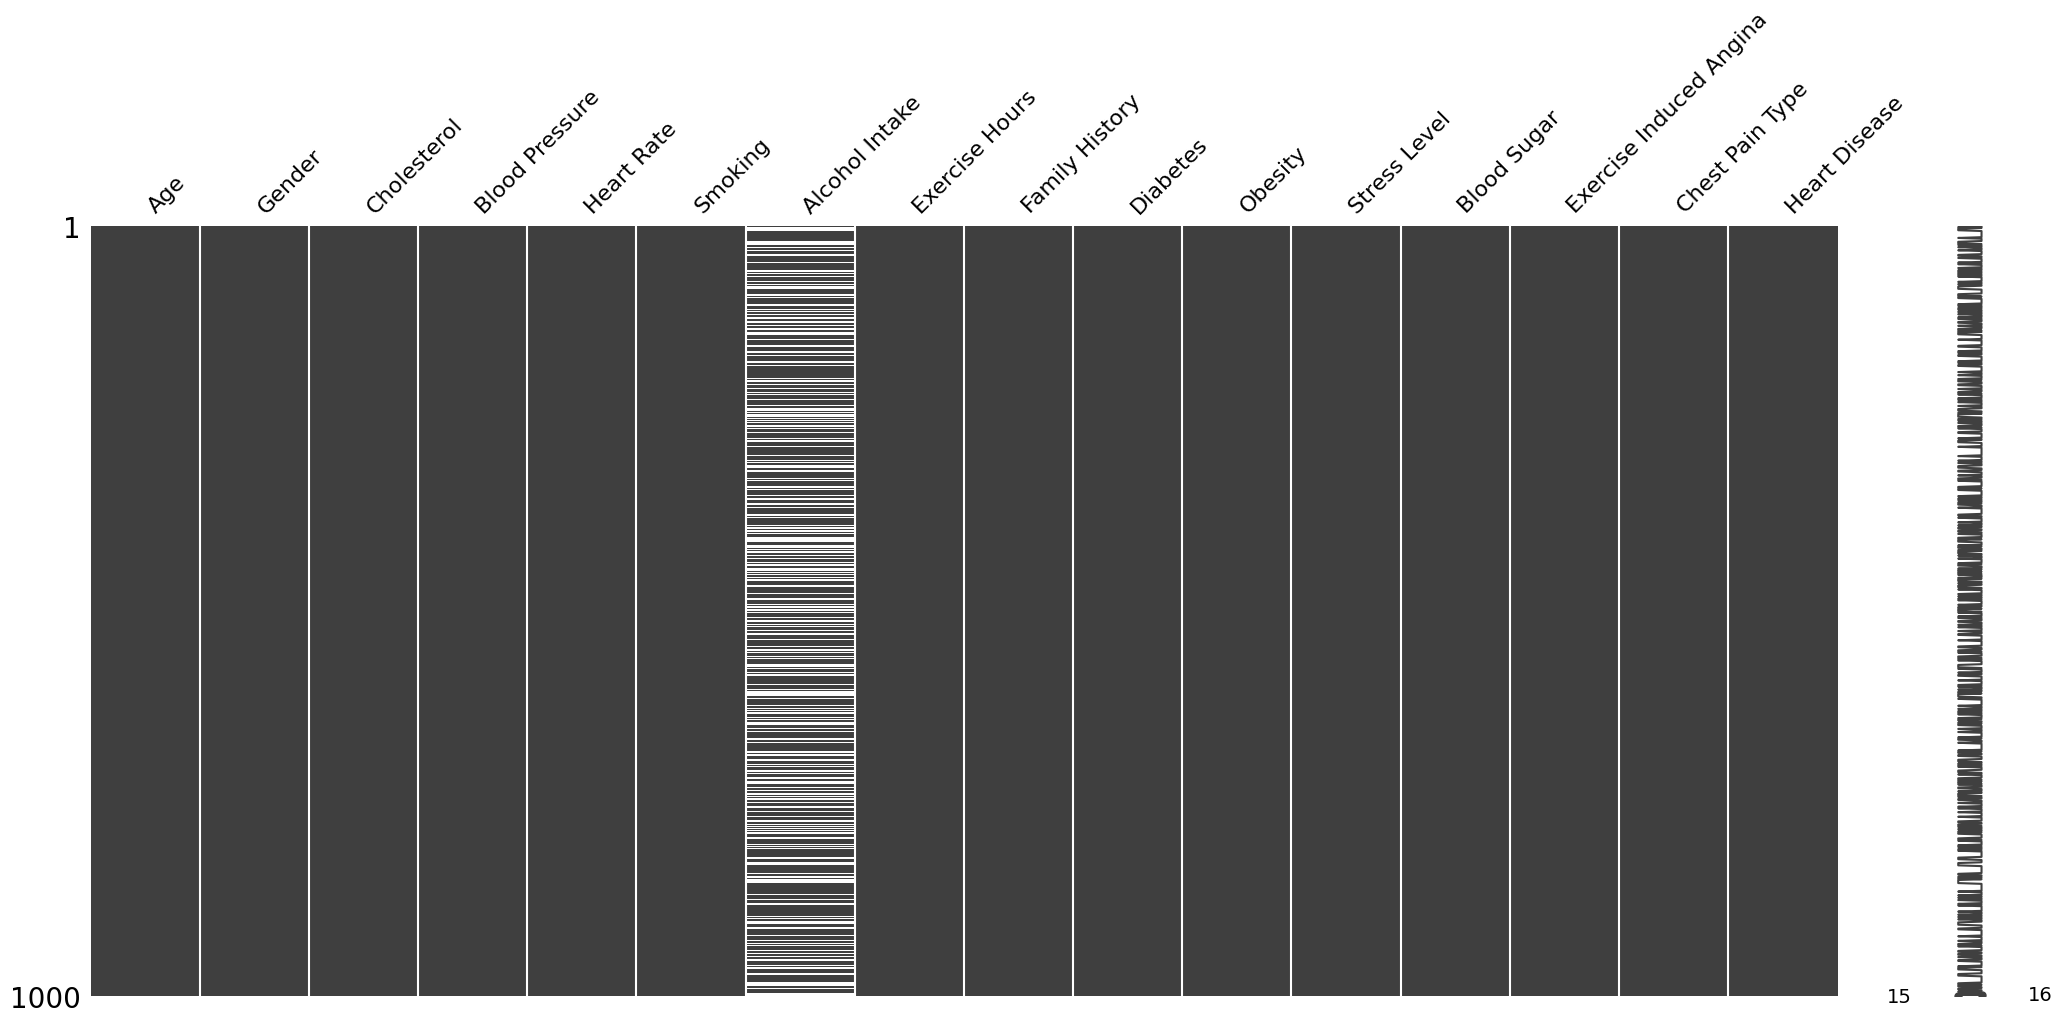

In [45]:
msno.matrix(df)
plt.show()

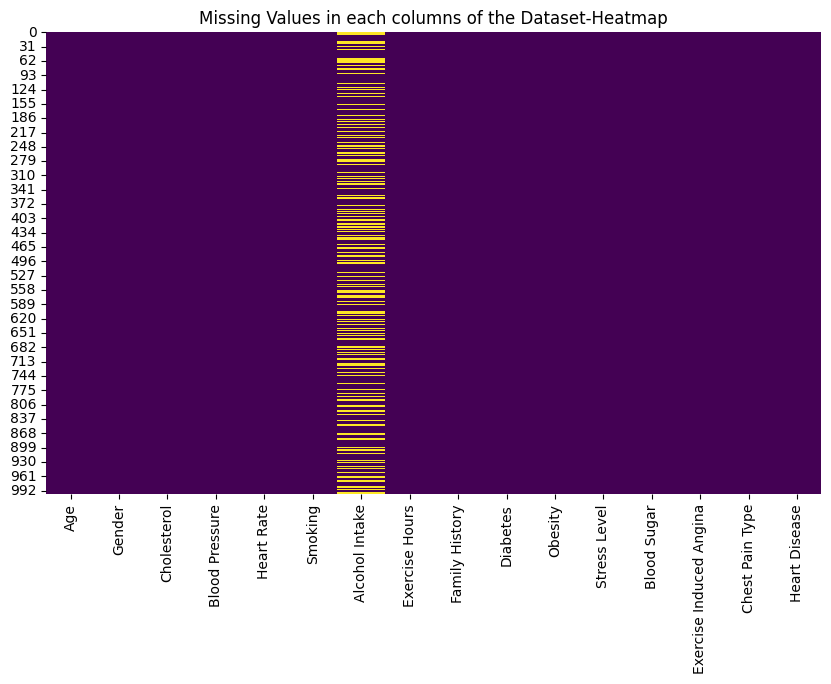

In [46]:
plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(),cmap='viridis',cbar=False)
plt.title("Missing Values in each columns of the Dataset-Heatmap")
plt.show()

In [47]:
df.isnull().sum().sum()

np.int64(340)

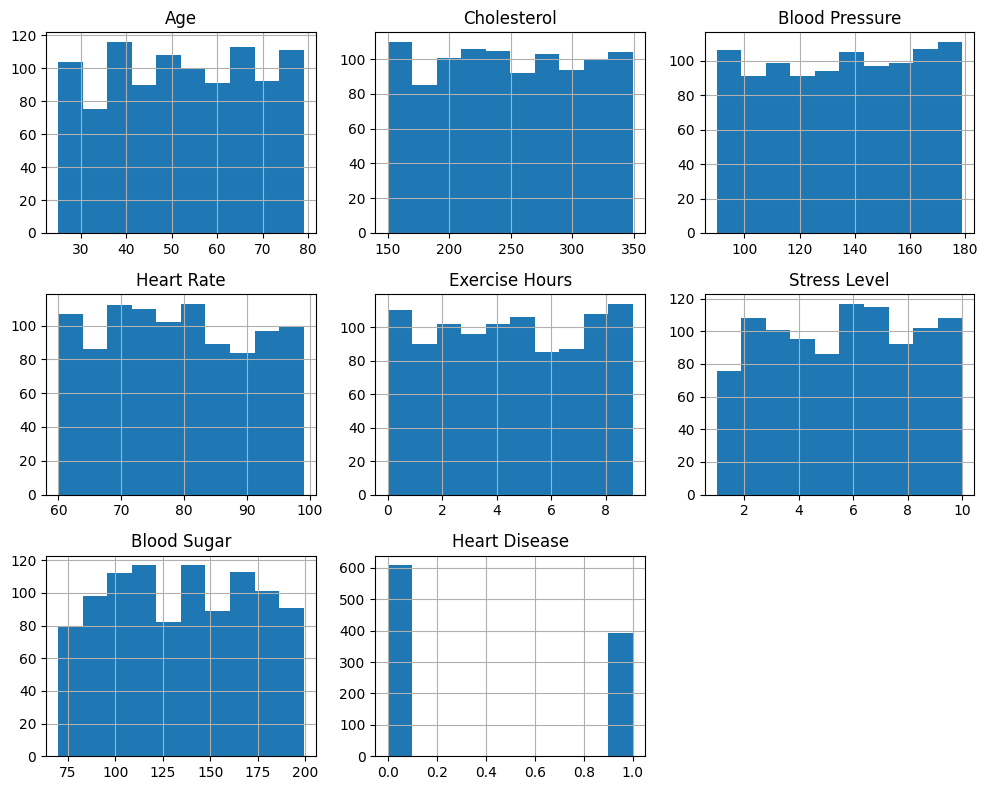

In [48]:
df.hist(figsize=(10,8))
plt.tight_layout()
plt.show()

In [49]:
print("Original shape:",df.shape)
df_drop=df.dropna()
print("Shape after removing missing values:",df_drop.shape)
print("\nMissing values after dropna():")
print(df_drop.isnull().sum())

Original shape: (1000, 16)
Shape after removing missing values: (660, 16)

Missing values after dropna():
Age                        0
Gender                     0
Cholesterol                0
Blood Pressure             0
Heart Rate                 0
Smoking                    0
Alcohol Intake             0
Exercise Hours             0
Family History             0
Diabetes                   0
Obesity                    0
Stress Level               0
Blood Sugar                0
Exercise Induced Angina    0
Chest Pain Type            0
Heart Disease              0
dtype: int64


In [50]:
missing_index = df[df["Alcohol Intake"].isnull()].index

original_values = df.loc[missing_index, "Alcohol Intake"].copy()

df["Alcohol Intake"] = df["Alcohol Intake"].fillna("Unknown")

print("Missing value indices:")
print(missing_index)

print("\nOriginal missing values:")
print(original_values)

Missing value indices:
Index([  1,   3,   4,   5,  15,  20,  21,  22,  24,  27,
       ...
       982, 983, 985, 986, 989, 990, 993, 996, 998, 999],
      dtype='int64', length=340)

Original missing values:
1      NaN
3      NaN
4      NaN
5      NaN
15     NaN
      ... 
990    NaN
993    NaN
996    NaN
998    NaN
999    NaN
Name: Alcohol Intake, Length: 340, dtype: object


In [51]:
df.isnull().sum()

,0
Age,0
Gender,0
Cholesterol,0
Blood Pressure,0
Heart Rate,0
Smoking,0
Alcohol Intake,0
Exercise Hours,0
Family History,0
Diabetes,0


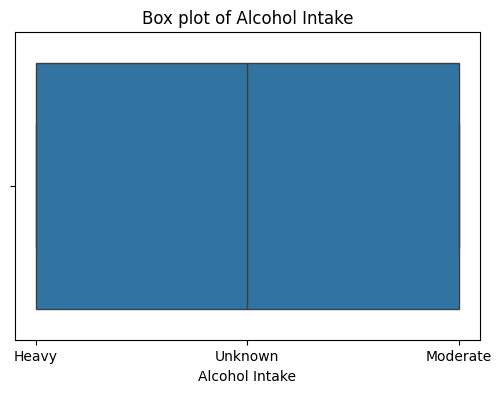

In [52]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["Alcohol Intake"])
plt.title("Box plot of Alcohol Intake")
plt.show()

In [53]:
numerical_columns = [
    "Age",
    "Cholesterol",
    "Blood Pressure",
    "Heart Rate",
    "Exercise Hours",
    "Stress Level",
    "Blood Sugar"
]

for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) | (df[col] > upper_limit)
    ]

    print("\nColumn:", col)
    print("Q1 =", Q1)
    print("Q3 =", Q3)
    print("IQR =", IQR)
    print("Lower Limit =", lower_limit)
    print("Upper Limit =", upper_limit)
    print("Total Outliers =", len(outliers))


Column: Age
Q1 = 39.0
Q3 = 66.0
IQR = 27.0
Lower Limit = -1.5
Upper Limit = 106.5
Total Outliers = 0

Column: Cholesterol
Q1 = 200.0
Q3 = 299.0
IQR = 99.0
Lower Limit = 51.5
Upper Limit = 447.5
Total Outliers = 0

Column: Blood Pressure
Q1 = 112.75
Q3 = 159.0
IQR = 46.25
Lower Limit = 43.375
Upper Limit = 228.375
Total Outliers = 0

Column: Heart Rate
Q1 = 70.0
Q3 = 89.0
IQR = 19.0
Lower Limit = 41.5
Upper Limit = 117.5
Total Outliers = 0

Column: Exercise Hours
Q1 = 2.0
Q3 = 7.0
IQR = 5.0
Lower Limit = -5.5
Upper Limit = 14.5
Total Outliers = 0

Column: Stress Level
Q1 = 3.0
Q3 = 8.0
IQR = 5.0
Lower Limit = -4.5
Upper Limit = 15.5
Total Outliers = 0

Column: Blood Sugar
Q1 = 104.0
Q3 = 167.0
IQR = 63.0
Lower Limit = 9.5
Upper Limit = 261.5
Total Outliers = 0


In [54]:
print(df.duplicated().sum())

0


In [55]:
df=df.drop_duplicates()
print(df.duplicated().sum())


0


In [56]:
# Binary encoding
binary_columns = [
    "Gender",
    "Family History",
    "Diabetes",
    "Obesity",
    "Exercise Induced Angina"
]

for col in binary_columns:
    df[col] = df[col].map({
        "No": 0,
        "Yes": 1,
        "Female": 0,
        "Male": 1
    })

# One-hot encoding
multi_columns = [
    "Smoking",
    "Alcohol Intake",
    "Chest Pain Type"
]

df = pd.get_dummies(df, columns=multi_columns, dtype=int)

print(df.head())

   Age  Gender  Cholesterol  Blood Pressure  Heart Rate  Exercise Hours  \
0   75       0          228             119          66               1   
1   48       1          204             165          62               5   
2   53       1          234              91          67               3   
3   69       0          192              90          72               4   
4   62       0          172             163          93               6   

   Family History  Diabetes  Obesity  Stress Level  ...  Smoking_Current  \
0               0         0        1             8  ...                1   
1               0         0        0             9  ...                1   
2               1         0        1             5  ...                0   
3               0         1        0             7  ...                1   
4               0         1        0             2  ...                0   

   Smoking_Former  Smoking_Never  Alcohol Intake_Heavy  \
0               0              0  

In [57]:
print(df.select_dtypes(include="object").columns)

Index([], dtype='object')


In [58]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [59]:
X = df.drop("Heart Disease", axis=1)
y = df["Heart Disease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 22)
Testing data: (200, 22)


In [60]:

numerical_columns = [
    "Age",
    "Cholesterol",
    "Blood Pressure",
    "Heart Rate",
    "Exercise Hours",
    "Stress Level",
    "Blood Sugar"
]

scaler = StandardScaler()

X_train[numerical_columns] = scaler.fit_transform(
    X_train[numerical_columns]
)

X_test[numerical_columns] = scaler.transform(
    X_test[numerical_columns]
)

print(X_train.head())

          Age  Gender  Cholesterol  Blood Pressure  Heart Rate  \
634 -0.467117       0    -1.499953       -1.063988    0.483258   
730  1.521298       1     0.065185       -0.302092   -0.126257   
893 -1.621681       0    -0.055210        0.916942   -0.387477   
688 -1.685823       1    -1.585950        1.526459   -1.084065   
27   0.687446       1     0.409172       -1.254462   -1.345285   

     Exercise Hours  Family History  Diabetes  Obesity  Stress Level  ...  \
634       -0.489909               1         0        1      0.488877  ...   
730       -0.152622               1         1        0      0.845722  ...   
893       -0.827196               0         1        1     -0.224812  ...   
688       -0.152622               0         1        0      0.845722  ...   
27         0.521952               1         1        1      1.202567  ...   

     Smoking_Current  Smoking_Former  Smoking_Never  Alcohol Intake_Heavy  \
634                1               0              0            

In [61]:
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression()

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [62]:
# Predict using testing data
y_pred = model.predict(X_test)

# Display predicted values
print("Predicted Values:")
print(y_pred)

Predicted Values:
[1 0 0 0 1 0 1 1 0 0 0 0 0 0 0 1 1 0 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0
 0 1 0 0 1 1 0 1 0 0 0 1 1 1 1 1 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 1
 0 1 0 1 1 0 0 0 0 1 0 0 0 1 1 0 0 0 0 1 0 0 1 0 1 1 1 0 1 1 1 1 0 0 1 0 0
 0 0 0 1 0 1 1 0 0 0 1 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 1 0 0 1 0 1 0 0 0 1 0
 0 0 0 0 1 1 0 0 0 1 0 0 1 0 0 1 1 0 0 1 1 0 0 0 0 1 1 0 1 0 1 0 1 1 1 0 1
 0 1 0 1 0 1 0 0 0 1 1 0 0 0 0]


In [63]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 86.0 %


In [64]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[111  11]
 [ 17  61]]


In [65]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.91      0.89       122
           1       0.85      0.78      0.81        78

    accuracy                           0.86       200
   macro avg       0.86      0.85      0.85       200
weighted avg       0.86      0.86      0.86       200



In [66]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy * 100, "%")

Random Forest Accuracy: 99.0 %


In [67]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       122
           1       1.00      0.97      0.99        78

    accuracy                           0.99       200
   macro avg       0.99      0.99      0.99       200
weighted avg       0.99      0.99      0.99       200



In [68]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, rf_pred))

[[122   0]
 [  2  76]]


In [69]:
print("Training accuracy:", rf_model.score(X_train, y_train) * 100)
print("Testing accuracy:", rf_model.score(X_test, y_test) * 100)

Training accuracy: 100.0
Testing accuracy: 99.0


In [70]:
new_data = X_test.iloc[[0]]

prediction = rf_model.predict(new_data)

print("Predicted Heart Disease:", prediction[0])

if prediction[0] == 1:
    print("Prediction: Heart Disease")
else:
    print("Prediction: No Heart Disease")

Predicted Heart Disease: 1
Prediction: Heart Disease


In [71]:
print("Actual Value:", y_test.iloc[0])
print("Predicted Value:", prediction[0])

Actual Value: 1
Predicted Value: 1


In [72]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print(feature_importance)

                             Feature  Importance
0                                Age    0.505405
2                        Cholesterol    0.258494
3                     Blood Pressure    0.036574
10                       Blood Sugar    0.036064
4                         Heart Rate    0.033582
5                     Exercise Hours    0.023102
9                       Stress Level    0.021930
1                             Gender    0.007413
6                     Family History    0.007211
13                    Smoking_Former    0.006656
11           Exercise Induced Angina    0.006324
7                           Diabetes    0.006174
20  Chest Pain Type_Non-anginal Pain    0.005926
14                     Smoking_Never    0.005782
19   Chest Pain Type_Atypical Angina    0.005553
16           Alcohol Intake_Moderate    0.005423
8                            Obesity    0.005308
18      Chest Pain Type_Asymptomatic    0.005271
12                   Smoking_Current    0.004872
15              Alco

In [73]:
print(df.groupby("Heart Disease")[["Age", "Cholesterol"]].mean())

                     Age  Cholesterol
Heart Disease                        
0              44.128289   232.972039
1              64.956633   276.255102


In [74]:
print(df.corr()["Heart Disease"].sort_values(ascending=False))

Heart Disease                       1.000000
Age                                 0.646871
Cholesterol                         0.365041
Alcohol Intake_Moderate             0.061400
Smoking_Never                       0.045485
Smoking_Current                     0.044615
Family History                      0.030283
Gender                              0.029399
Chest Pain Type_Asymptomatic        0.022691
Chest Pain Type_Atypical Angina     0.016970
Diabetes                            0.016552
Heart Rate                          0.013209
Chest Pain Type_Typical Angina      0.009461
Stress Level                        0.007071
Blood Pressure                      0.006900
Exercise Induced Angina             0.004005
Blood Sugar                        -0.013004
Alcohol Intake_Unknown             -0.014183
Exercise Hours                     -0.014226
Obesity                            -0.018878
Alcohol Intake_Heavy               -0.045782
Chest Pain Type_Non-anginal Pain   -0.048587
Smoking_Fo

In [75]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    rf_model, X_train, y_train, cv=5, scoring="accuracy"
)

print("Cross Validation Scores:", cv_scores)
print("Average CV Accuracy:", cv_scores.mean() * 100, "%")

Cross Validation Scores: [1.      1.      1.      1.      0.99375]
Average CV Accuracy: 99.875 %


In [76]:
import joblib

joblib.dump(rf_model, "heart_disease_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [77]:
joblib.dump(scaler, "heart_disease_scaler.pkl")
print("Scaler saved successfully!")

Scaler saved successfully!
